# Performing curation and analyze iModulons that might be associated with ethanol production. Only the imodulons of interest from OLS (p1)

In [ ]:
from pymodulon.io import *
from pymodulon.plotting import *

import seaborn as sns
print(sns.__version__)

from pymodulon.enrichment import compute_enrichment, compute_annotation_enrichment

from pymodulon.motif import *
from pymodulon.example_data import load_ecoli_data, ecoli_fasta

from os import path

import numpy as np
import pandas as pd

0.13.2


'1.13.1'

In [4]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

### LOAD THE DATA

In [5]:
data_dir = path.join('..', 'ctherm_nf','processed_data')

In [6]:
ica_data = load_json_model(path.join(data_dir, 'ctherm.json.gz')) #adjusted

### gene info
df_gene_info = pd.read_csv(path.join(data_dir, 'gene_info.csv'), index_col=0)
df_gene_info.head()

/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/p

,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs
locus_tag,,,,,,,,,,,,,,
Clo1313_0001,dnaA,CP002416.1,NaN,212,1543,+,chromosomal replication initiator protein DnaA,No COG annotation,UPI0001B1F046,Op0,ATP binding; DNA replication origin binding; l...,DNA replication initiation; regulation of DNA ...,AAA+_ATPase;Chromosome_initiator_DnaA;Chromoso...,NaN
Clo1313_0002,RS00015,CP002416.1,NaN,1793,2893,+,DNA polymerase III%2C beta subunit,No COG annotation,UPI00017E1F7F,Op1,NaN,NaN,DNA_clamp_sf;DNA_polIII_beta;DNA_polIII_beta_C...,NaN
Clo1313_0003,yaaA,CP002416.1,NaN,2909,3115,+,S4 domain protein YaaA,No COG annotation,UPI000038F4E6,Op1,NaN,NaN,RNA-bd_S4-rel_YaaA;S4_RNA-bd;S4_RNA-bd_sf;,NaN
Clo1313_0004,recF,CP002416.1,NaN,3133,4242,+,DNA replication and repair protein RecF,No COG annotation,UPI00003C8C54,Op1,ATP binding; single-stranded DNA binding,DNA replication; DNA synthesis involved in DNA...,DNA-binding_RecF;DNA-binding_RecF_CS;P-loop_NT...,NaN
Clo1313_0005,RS00030,CP002416.1,NaN,4410,4724,+,hypothetical protein,Function unknown,UPI000038F4E8,Op2,NaN,NaN,RemA-like;,DUF370


### First rename the imodulon

In [7]:
df_rename_imod = pd.read_csv('./results_characterize_imodulons/imod_rename_mapping.tsv', sep='\t', index_col=0)
dict_rename_imod = df_rename_imod[['IM']].to_dict()['IM']

# rename all at once
ica_data.rename_imodulons(dict_rename_imod)

# set IM as index for this work
df_rename_imod.set_index('IM', inplace=True)

# GRN for regulation in C. thermocellum
for i,row in ica_data.imodulon_table.iterrows():
    if pd.notnull(row.regulator):
        ica_data.imodulon_table.loc[i, 'category'] = 'regulatory'
    else:
        ica_data.imodulon_table.loc[i, 'category'] = df_rename_imod.loc[i, 'category']



### metadata and ethanol data for projects of interest

In [ ]:
df_metadata = ica_data.sample_table
df_expression = ica_data.X

### Load the data to identify significant IMs. This contains samples per experiment. Replicates are averaged out

In [ ]:
df_imod_activity_eth_collapsed = pd.read_csv('./required_data/df_results_collapsed_exp_eh_evo.tsv', sep='\t', index_col=0)

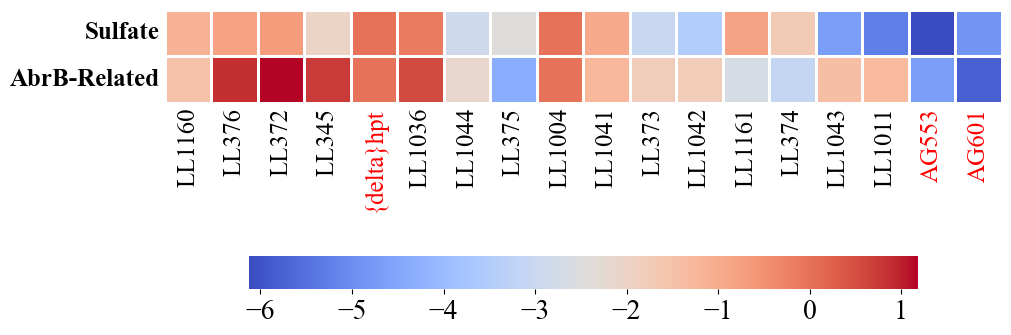

In [ ]:
significant_ims = ['Sulfate', 'AbrB-Related']

df_imod_activity_of_interest_plot = df_imod_activity_eth_collapsed.copy()
df_imod_activity_of_interest_plot['project'] = [k.split(' - ')[0] for k in df_imod_activity_of_interest_plot.index]
df_imod_activity_of_interest_plot = df_imod_activity_of_interest_plot[significant_ims + ['Ethanol_g_L', 'project', 'strain']]
df_imod_activity_of_interest_plot.drop_duplicates('strain', inplace=True)
df_imod_activity_of_interest_plot.set_index('strain', inplace=True)
# sort by ethanol levels
df_imod_activity_of_interest_plot.sort_values('Ethanol_g_L', ascending=True, inplace=True)

fig, ax = plt.subplots(1, 1, figsize=(10, 10), constrained_layout=True)

# Drawing the heatmap with the mask
ax = sns.heatmap(
    df_imod_activity_of_interest_plot[significant_ims].T, 
    cmap='coolwarm',    # Good colormap for positive/negative correlations
    cbar_kws={'orientation': 'horizontal', 'shrink': 0.8},
    square=True,        # Makes each cell perfectly square
    linewidths=0.8      # Adds thin borders between squares
)

# Remove the x-axis label title
ax.set(xlabel=None)

# Remove tick marks but keep labels with certain label size for both axes
ax.tick_params(axis='both', length=0, labelsize=18)
ax.tick_params(axis='x', rotation=90)

# change the weight of each
ax.set_yticklabels([f'{k}' for k in significant_ims], weight='bold')

# Access the colorbar object
cbar = ax.collections[0].colorbar

# Rotate y-tick labels by 45 degrees
cbar.ax.tick_params(labelsize=20)

# Define a color map dictionary
group_colors = {'eh_chemostat': 'black', 'evo_ag553_ag601': 'red'}

# 4. Iterate over the tick labels and apply the group colors
for tick_label in ax.get_xticklabels():
    col_name = tick_label.get_text()
    
    group = df_imod_activity_of_interest_plot.loc[col_name, 'project']
    if group:
        tick_label.set_color(group_colors[group])

# plt.savefig('./results_characterize_imodulons/heatmap_im_v_etoh_sulfate_abrb.png', transparent=True, pad_inches=0.01, dpi=300, format='png')
plt.show()

### Looking at the IM activity for IMs of interest

In [ ]:
# prepare data for plotting
proj_of_interest = ['sulfate']
cond_of_interest = ['del_hpt_sulf', 'del_hpt_cys']
cols_of_interest = ['Sulfate', 'AbrB-Related']

dict_imod_activities = dict() #dictionary to store all

for col_of_interest in cols_of_interest:
    df_imod_activity_eth = pd.DataFrame()

    df_metadata_eh = df_metadata.loc[df_metadata.project.isin(proj_of_interest)]
    df_metadata_eh = df_metadata_eh.loc[~(df_metadata_eh['condition']=='wt_nlim')] #don't have information on this
    df_metadata_eh = df_metadata_eh.loc[df_metadata_eh['condition'].isin(cond_of_interest)]


    # # only focus on the exp_of_interest
    exp_of_interest = df_metadata_eh.index.to_list()
    df_activity = pd.read_csv(path.join(data_dir, 'A.csv'), index_col=0)
    df_activity = df_activity[exp_of_interest]

    for imod in df_activity.index.to_list():
        values = df_activity.loc[imod]
        df_imod_activity_eth[imod] = values

    df_imod_activity_eth['condition'] = df_metadata_eh.condition.astype(str)
    df_imod_activity_eth['full_name'] = df_metadata_eh.project.astype(str) + ' - ' + df_metadata_eh.condition.astype(str)

    # rename imod columsn
    df_imod_activity_eth.rename(columns=dict_rename_imod, inplace=True)

    # keep the column of interest
    df_imod_activity_eth = df_imod_activity_eth[[col_of_interest, 'condition']]
    df_data_points = df_imod_activity_eth.groupby('condition')[col_of_interest].apply(list)

    # change the name of indices
    df_data_points.rename(index={'del_hpt_cys': 'Cysteine', 'del_hpt_sulf': 'Sulfate'}, inplace=True)

    dict_imod_activities[col_of_interest] = df_data_points


/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_78306/2313359882.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([k for k in dict_imod_activities.keys()], size=20, weight='bold')
/var/folders/8c/yy8ts7rn59j58vl5_l6jgcmd1lvs3b/T/ipykernel_78306/2313359882.py:40: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


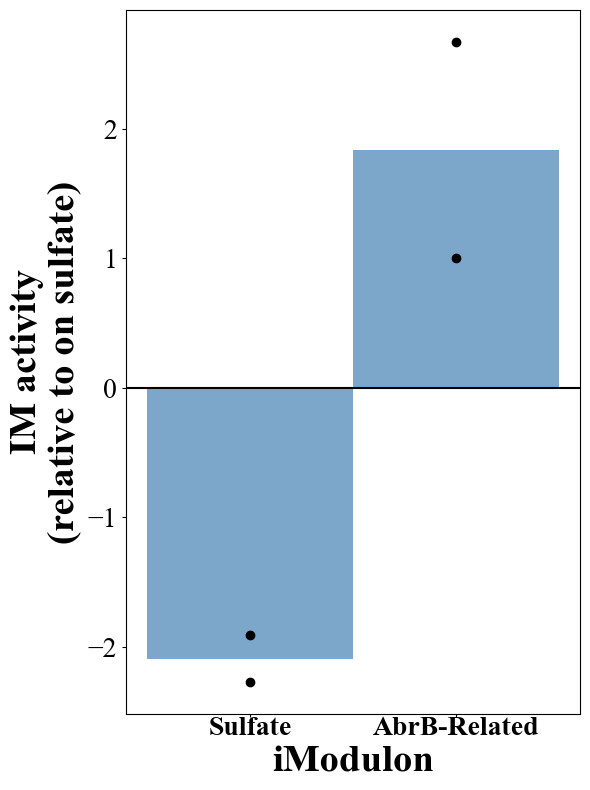

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 8), constrained_layout=True)


for name, values in dict_imod_activities.items():
    val = values['Cysteine']
    ax.bar(
        name,
        np.mean(val),
        color=['steelblue', 'salmon'], 
        alpha=0.7,
        width=1,
        linewidth=0.1,
        align='center',
        zorder=0.1,
        label=name,
    )
    ax.scatter([name] * len(val), val, color="black", zorder=3)

# # add a horizontal line
ax.axhline(y=0, color='k')

# # x-axis and y-axis label
ax.set_ylabel(f'IM activity\n(relative to on sulfate)', fontdict={'size':28, 'weight':'bold'})
ax.set_xlabel(f'iModulon', fontdict={'size':28, 'weight':'bold'})

# # Remove tick marks but keep labels with certain label size for both axes
ax.tick_params(axis='y', length=3, labelsize=20)
ax.tick_params(axis='x', which='major', length=2, pad=0.5)

ax.set_xticklabels([k for k in dict_imod_activities.keys()], size=20, weight='bold')


plt.tight_layout()

# save it
# plt.savefig('./results_characterize_imodulons/im_sulfate_abrb_act_sulfate_proj.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

### FIN